# Sundarbans channel networks 2016–2026: weighted, simplified G1…G10 and the baseline

This notebook redoes `main.ipynb` on the **simplified, weighted** graphs. `main.ipynb` and `Results/timeseries/` are left as they were; everything here is saved in `Results/timeseries_weighted/`.

For each image in `Data/` (October–November, 2016–2026; 2018 is skipped):

1. extract the cleaned RivGraph network, the same way as in `main.ipynb`,
2. add weights: `conductance` = width / length, and `weight` = conductance ÷ the graph's largest conductance,
3. contract redundant links with the thresholds in `sundarbans_simplified_network.py`, which gives **G1 … G10**,
4. build the **baseline B1 … B10**: a random tree on the same year's nodes,
5. compare them over the years.

**Simplification settings (the file's defaults):**
* Pass 1: contract the highest-weight links above median + 2 × 1.4826 × MAD, at most 7 per graph.
* Pass 2: contract links shorter than 120 m.
* Inlets and outlets are never contracted, real loops are never deleted, and **no node has a self-edge**.

**Which graph is used for which parameter:**
* Parameters that **don't need weights** (cycles, bridges, paths in links, and so on) use the **unweighted** graphs.
* Parameters that **do need weights** use **`conductance`**, not `weight`. `weight` is scaled by each graph's own maximum, so it can't be compared between years.

Runs on Colab from `MyDrive/Mangrove_Maze`: run SETUP first, then the cells in order.

In [2]:
# SETUP - Mount Drive, move into Mangrove_Maze, install packages from the wheelhouse
# WHEN: first cell of every session. Needs wheels_py313/ (built once by Mangroves.ipynb).
# NOTE: if the install lines print "Uninstalling numpy/scipy/pandas", do
#       Runtime -> Restart session, then run this cell again (the second run installs nothing).
# NEEDS: sundarbans_rg.py, tree_nulls.py and sundarbans_simplified_network.py in Mangrove_Maze/.
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/Mangrove_Maze
!pip install --no-index --find-links=wheels_py313 -r requirements-py313.txt 2>&1 | grep -E "Uninstalling|Successfully installed|ERROR"
!pip install --no-index --no-deps --find-links=wheels_py313 rivgraph 2>&1 | tail -1
import os
missing = [m for m in ('sundarbans_rg.py', 'tree_nulls.py', 'sundarbans_simplified_network.py') if not os.path.exists(m)]
assert not missing, f'upload {missing} to MyDrive/Mangrove_Maze first'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Mangrove_Maze


In [3]:
import glob, re, os, pickle, warnings
from datetime import datetime
import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import sundarbans_rg as srg
import tree_nulls as tn
from sundarbans_simplified_network import (build_simplified_network, to_unweighted, load_graphs,
                                           assign_baseline_weights, count_cycles)
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

OUT = 'Results/timeseries_weighted'        # inside MyDrive/Mangrove_Maze
os.makedirs(f'{OUT}/graphs', exist_ok=True)

def image_date(path):
    return datetime.strptime(os.path.basename(path)[:10], '%Y-%m-%d')   # Data/2016-10-17-00_00_..._NDWI.tiff

SKIP_YEARS = {2018}                               # left out as in main.ipynb; the plot grids below expect 10 images
files = sorted((f for f in glob.glob('Data/*.tif*') if image_date(f).year not in SKIP_YEARS), key=image_date)
index = pd.DataFrame({'graph': [f'G{k}' for k in range(1, len(files) + 1)],
                      'baseline': [f'B{k}' for k in range(1, len(files) + 1)],
                      'date': [image_date(f).date() for f in files], 'file': files})
index

,graph,baseline,date,file
0,G1,B1,2016-10-17,Data/2016-10-17-00_00_2016-10-17-23_59_Sentine...
1,G2,B2,2017-10-17,Data/2017-10-17-00_00_2017-10-17-23_59_Sentine...
2,G3,B3,2019-11-16,Data/2019-11-16-00_00_2019-11-16-23_59_Sentine...
3,G4,B4,2020-11-15,Data/2020-11-15-00_00_2020-11-15-23_59_Sentine...
4,G5,B5,2021-11-10,Data/2021-11-10-00_00_2021-11-10-23_59_Sentine...
5,G6,B6,2022-10-21,Data/2022-10-21-00_00_2022-10-21-23_59_Sentine...
6,G7,B7,2023-10-16,Data/2023-10-16-00_00_2023-10-16-23_59_Sentine...
7,G8,B8,2024-11-14,Data/2024-11-14-00_00_2024-11-14-23_59_Sentine...
8,G9,B9,2025-10-22,Data/2025-10-22-00_00_2025-10-22-23_59_Sentine...
9,G10,B10,2026-10-20,Data/2026-10-20-00_00_2026-10-20-23_59_Sentine...


## 1. Common grid and shoreline

In [4]:
grid = srg.common_grid(files)
shore, _ = srg.common_shoreline(files, grid, f'{OUT}/shoreline_common.gpkg')
T = grid['transform']; H, W = grid['height'], grid['width']
EXT = [0, W * T.a / 1e3, 0, H * -T.e / 1e3]
print(f"common grid: {W} x {H} px at {T.a:.1f} x {-T.e:.1f} m = {EXT[1]:.1f} x {EXT[3]:.1f} km, {grid['crs']}")

common grid: 2414 x 1830 px at 30.2 x 30.5 m = 72.9 x 55.7 km, EPSG:32645


## 2. Build G1 … G10 and the baselines B1 … B10

The variables are dictionaries keyed by name, for example `G_und['G3']` or `B_und['B3']`:

| variable | contents |
|---|---|
| `G_und` | weighted, simplified G1–G10 (undirected) |
| `G_unw` | the same graphs without weights |
| `G_dir` | directed copies, same contractions |
| `B_und` | baseline trees, with geometry |
| `B_unw` | baseline trees without weights |

**Baseline geometry:** a random tree's links join arbitrary nodes, so they have no width or length of their own. Each baseline link is given the width and length of a different real link from that year, chosen at random. The baseline therefore has the same kind of channels as the real network, placed at random.

In [5]:
KIND_COL = {'inlet': '#2ca02c', 'outlet': '#ff7f0e', 'junction': '#444444'}
nets, G_und, G_unw, G_dir, B_und, B_unw, B_dir, inlets, outlets = {}, {}, {}, {}, {}, {}, {}, {}, {}
for k, row in index.iterrows():
    gname, bname = row['graph'], row['baseline']
    net = build_simplified_network(row['file'], f"{OUT}/{row['date']}", grid=grid, shoreline_path=f'{OUT}/shoreline_common.gpkg')
    nets[gname], G_und[gname], G_dir[gname] = net, net['G'], net['D']
    G_unw[gname] = to_unweighted(net['G'])
    inlets[gname], outlets[gname] = net['inlets'], net['outlets']
    rng = np.random.default_rng(k)                      # fixed seed -> the saved baseline is reproducible
    B_dir[bname], tree = tn.random_parent_tree(net['G'], net['inlets'], net['outlets'], rng)
    B_und[bname] = assign_baseline_weights(tree, net['G'], rng)
    B_unw[bname] = to_unweighted(tree)

assert all(nx.number_of_selfloops(g) == 0 for d in (G_und, G_unw, G_dir, B_und, B_unw) for g in d.values())
print('no graph has a self-edge')

counts = pd.DataFrame({g: {'date': index.set_index('graph').loc[g, 'date'],
                           'nodes before': nets[g]['G_raw'].number_of_nodes(), 'links before': nets[g]['G_raw'].number_of_edges(),
                           'nodes': G.number_of_nodes(), 'links': G.number_of_edges(),
                           'cycles before': count_cycles(nets[g]['G_raw']), 'cycles': count_cycles(G),
                           'contracted by weight': len(nets[g]['history_df']), 'contracted by length': len(nets[g]['spatial_history_df']),
                           'self-edges removed': nets[g]['self_edges_removed'],
                           'inlets': len(inlets[g]), 'outlets': len(outlets[g]),
                           'baseline links': B_und[g.replace('G', 'B')].number_of_edges()}
                       for g, G in G_und.items()}).T
counts.to_csv(f'{OUT}/graph_counts.csv')
counts

no graph has a self-edge


,date,nodes before,links before,nodes,links,cycles before,cycles,contracted by weight,contracted by length,self-edges removed,inlets,outlets,baseline links
G1,2016-10-17,142,176,135,169,35,35,7,0,0,14,23,112
G2,2017-10-17,136,167,129,160,32,32,7,0,0,15,22,107
G3,2019-11-16,169,209,162,202,41,41,7,0,0,18,27,135
G4,2020-11-15,171,211,164,204,41,41,7,0,0,19,27,137
G5,2021-11-10,168,206,161,199,39,39,7,0,0,18,28,133
G6,2022-10-21,170,210,163,203,41,41,7,0,0,19,26,137
G7,2023-10-16,145,175,138,168,31,31,7,0,0,18,25,113
G8,2024-11-14,139,169,132,162,31,31,7,0,0,14,26,106
G9,2025-10-22,165,204,158,197,40,40,7,0,0,17,27,131
G10,2026-10-20,172,212,165,205,41,41,7,0,0,18,29,136


### Save the graphs

All paths are inside `Results/timeseries_weighted/`.

| file | contents |
|---|---|
| `graphs/G{k}_{date}_weighted.graphml` | simplified graph. Nodes: `kind`, `x`, `y` (UTM 45N, m), `merged`. Links: `weight`, `conductance`, `length_m`, `width_m` |
| `graphs/G{k}_{date}_unweighted.graphml` | the same graph, links without attributes |
| `graphs/B{k}_{date}_weighted.graphml`, `..._unweighted.graphml` | the baseline tree, both ways |
| `graphs/all_graphs.pkl` | everything as networkx objects, weighted (`G_directed` and `B_directed` have no weights on B) |
| `graphs/index.csv` | G/B number ↔ date ↔ image file |

In [6]:
def for_graphml(g, weighted=True):
    h = nx.MultiGraph()
    for n, d in g.nodes(data=True):
        h.add_node(n, kind=d['kind'], x=float(d['pos'][0]), y=float(d['pos'][1]), merged=bool(d.get('merged', False)))
    for u, v, k, d in g.edges(keys=True, data=True):
        h.add_edge(u, v, key=k, **({'weight': float(d['weight']), 'conductance': float(d['conductance']),
                                    'length_m': float(d['length']), 'width_m': float(d['width'])} if weighted else {}))
    return h

for _, row in index.iterrows():
    for name, d in ((row['graph'], G_und), (row['baseline'], B_und)):
        nx.write_graphml(for_graphml(d[name]), f"{OUT}/graphs/{name}_{row['date']}_weighted.graphml")
        nx.write_graphml(for_graphml(d[name], weighted=False), f"{OUT}/graphs/{name}_{row['date']}_unweighted.graphml")
with open(f'{OUT}/graphs/all_graphs.pkl', 'wb') as fh:
    pickle.dump({'index': index, 'G': G_und, 'G_directed': G_dir, 'B': B_und, 'B_directed': B_dir,
                 'inlets': inlets, 'outlets': outlets}, fh)
index.to_csv(f'{OUT}/graphs/index.csv', index=False)
len(os.listdir(f'{OUT}/graphs'))

42

### Getting weighted or unweighted graphs later

You don't need to re-run this notebook. Either load the saved graphs, or strip the weights from a graph you already have:

In [7]:
PKL = f'{OUT}/graphs/all_graphs.pkl'
weighted = load_graphs(PKL)                          # {'G1': graph, ...} with weights
unweighted = load_graphs(PKL, weighted=False)        # same graphs, no weights
baseline_unweighted = load_graphs(PKL, weighted=False, baseline=True)

g = weighted['G3']; u = unweighted['G3']
u_simple = to_unweighted(g, simple=True)             # plain nx.Graph: merges parallel links, so it hides their loops
print('weighted link:  ', {k: round(v, 3) for k, v in next(iter(g.edges(data=True)))[2].items() if k in ('weight', 'conductance', 'length', 'width')})
print('unweighted link:', next(iter(u.edges(data=True)))[2])
print(f'cycles: weighted {count_cycles(g)}, unweighted {count_cycles(u)}, simple {count_cycles(u_simple)}')

weighted link:   {'length': np.float64(3348.275), 'width': np.float64(160.275), 'conductance': 0.048, 'weight': 0.001}
unweighted link: {}
cycles: weighted 41, unweighted 41, simple 39


## 3. The graphs: G1 … G10 (link thickness shows weight rank)

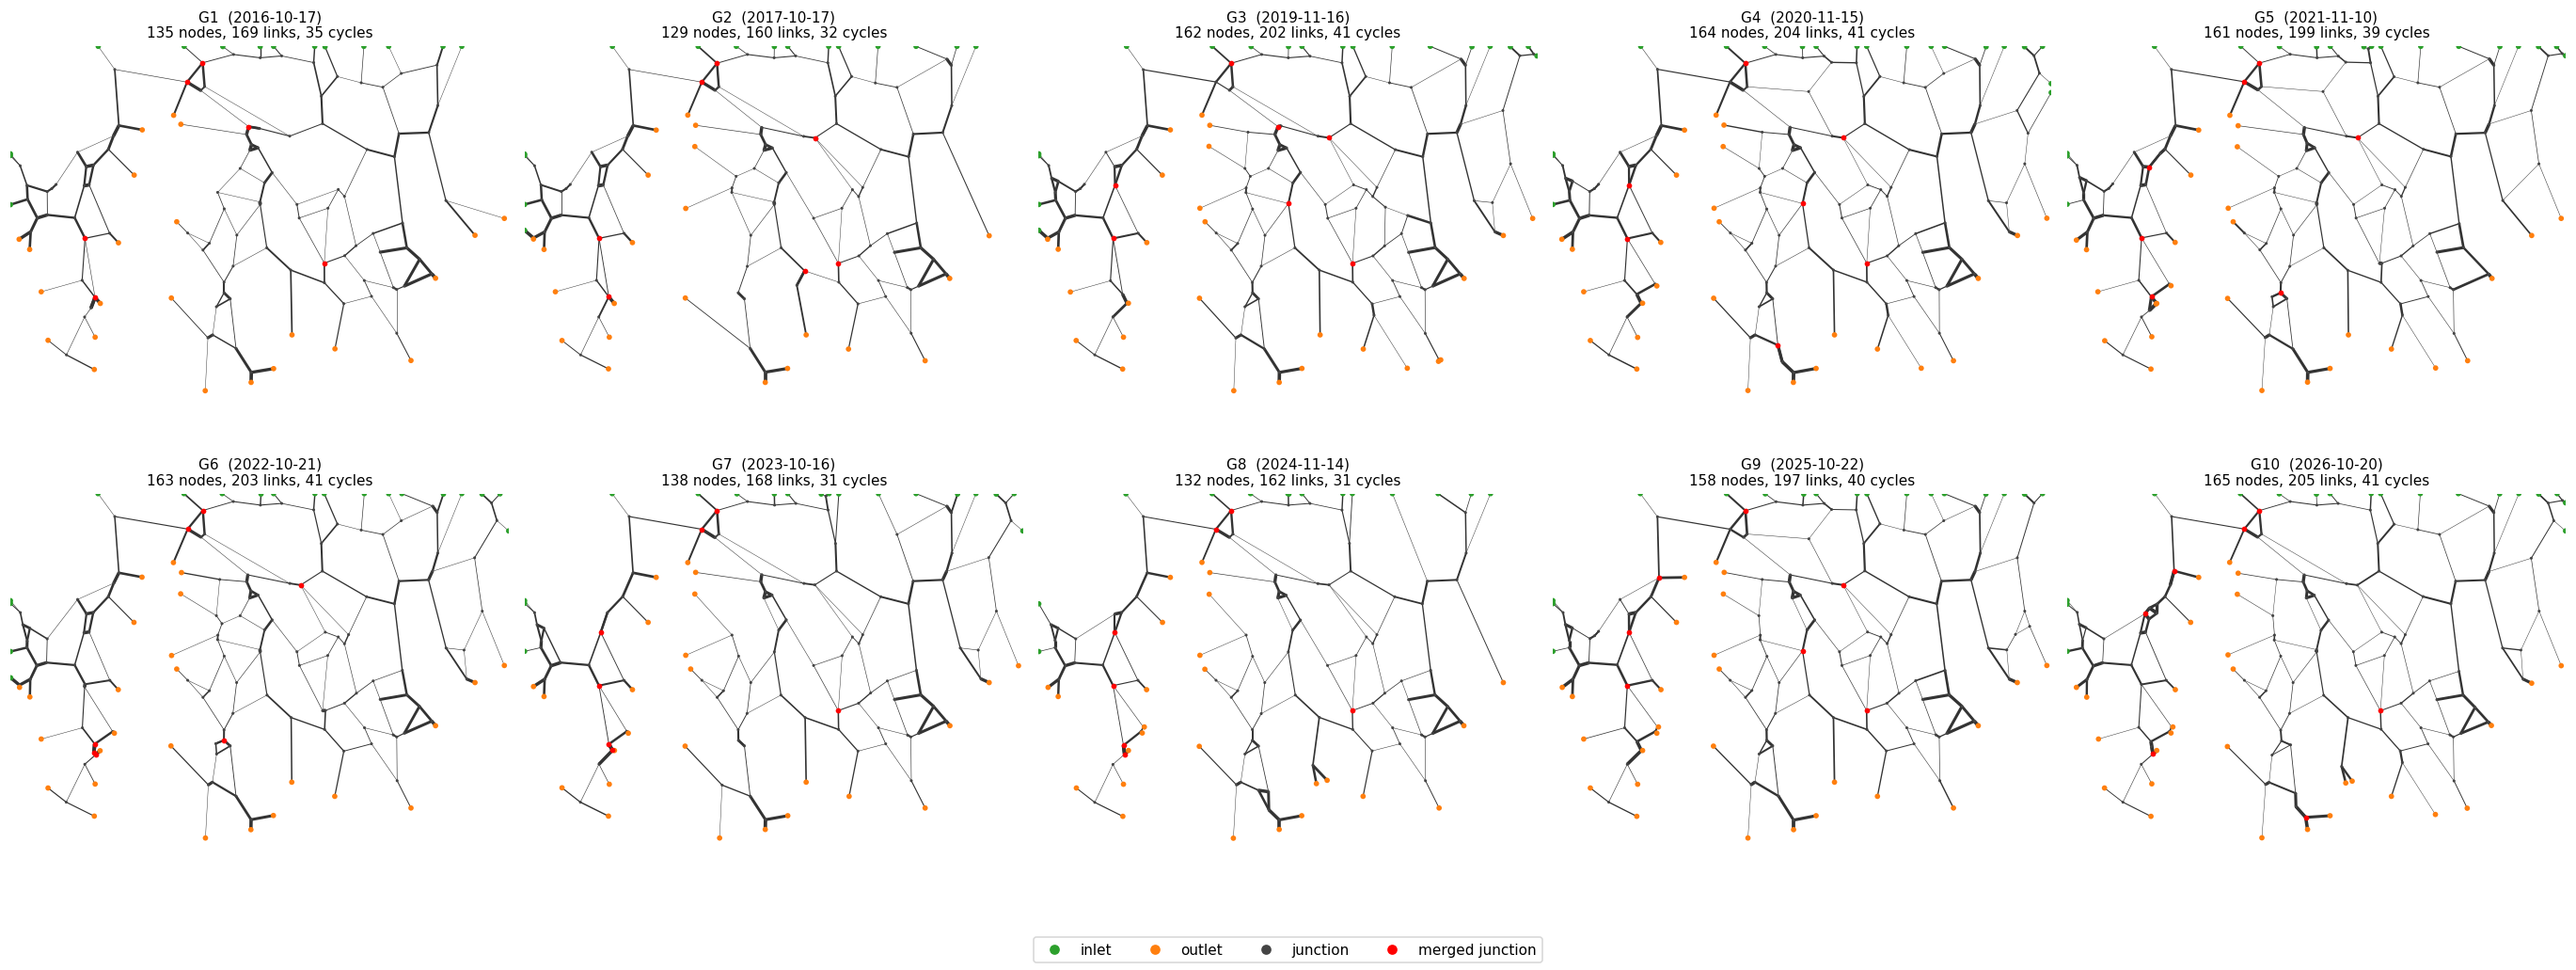

In [8]:
def km_pos(g):
    return {n: ((d['pos'][0] - T.c) / 1e3, (d['pos'][1] - (T.f + H * T.e)) / 1e3) for n, d in g.nodes(data=True)}

def draw_graph(g, ax, title, edge_color='#333'):
    pos = km_pos(g)
    rank = pd.Series([d['weight'] for *_, d in g.edges(data=True)]).rank(pct=True).values   # raw weights are dominated by a few estuary links
    nx.draw_networkx_edges(g, pos, ax=ax, edge_color=edge_color, width=0.3 + 2.2 * rank ** 2)
    nx.draw_networkx_nodes(g, pos, ax=ax, node_size=[14 if g.nodes[n]['kind'] != 'junction' else 4 for n in g],
                           node_color=[KIND_COL[g.nodes[n]['kind']] for n in g], linewidths=0)
    merged = [n for n in g if g.nodes[n].get('merged')]
    nx.draw_networkx_nodes(g, pos, nodelist=merged, ax=ax, node_size=14, node_color='red', linewidths=0)
    ax.set_xlim(EXT[:2]); ax.set_ylim(EXT[2:]); ax.set_aspect('equal'); ax.axis('off'); ax.set_title(title, fontsize=10)

legend = [Line2D([], [], marker='o', ls='', color=c, label=k) for k, c in {**KIND_COL, 'merged junction': 'red'}.items()]
fig, axs = plt.subplots(2, 5, figsize=(25, 9.5))
for ax, (_, row) in zip(axs.ravel(), index.iterrows()):
    g = G_und[row['graph']]
    draw_graph(g, ax, f"{row['graph']}  ({row['date']})\n{g.number_of_nodes()} nodes, {g.number_of_edges()} links, {count_cycles(g)} cycles")
fig.legend(handles=legend, loc='lower center', ncol=4); plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(f'{OUT}/G_all_years.png', dpi=110); plt.show()

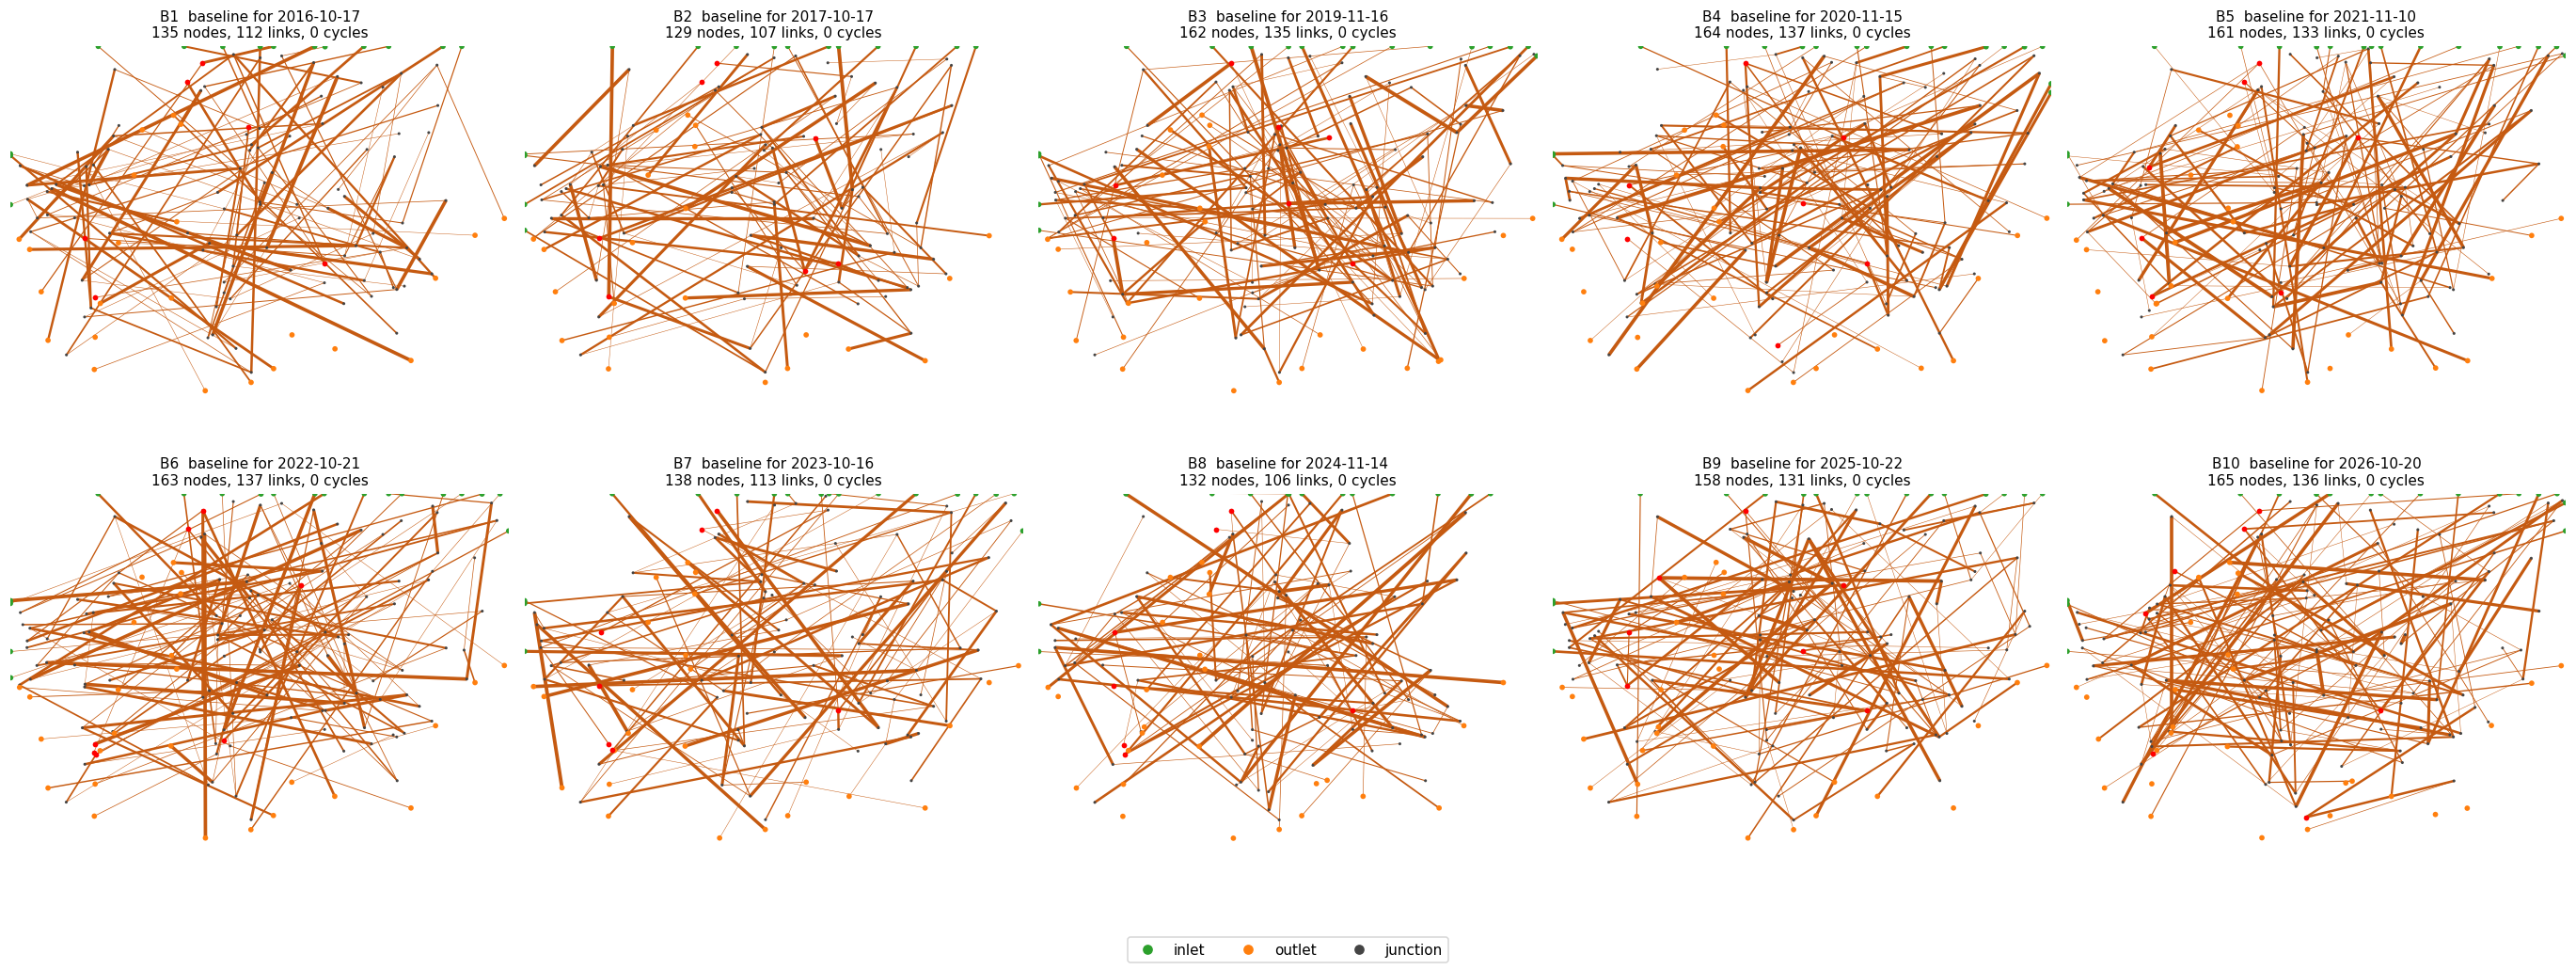

In [9]:
fig, axs = plt.subplots(2, 5, figsize=(25, 9.5))
for ax, (_, row) in zip(axs.ravel(), index.iterrows()):
    b = B_und[row['baseline']]
    draw_graph(b, ax, f"{row['baseline']}  baseline for {row['date']}\n{b.number_of_nodes()} nodes, {b.number_of_edges()} links, 0 cycles", edge_color='#c55a11')
fig.legend(handles=legend[:3], loc='lower center', ncol=3); plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(f'{OUT}/B_all_years.png', dpi=110); plt.show()

## 4. Parameters over the years: G vs the baseline

For each year: the parameters of **G<sub>k</sub>** and of **1,000 random baseline trees** on that year's nodes.

**Unweighted parameters** use the unweighted graphs: every link counts as 1. These are the same parameters as `main.ipynb`, with direction from the node farther from the sea to the node closer to it.

**Weighted parameters** use `conductance` = width / length, so each link has resistance L/w. A short, wide channel conducts easily and a long, narrow one doesn't.

| weighted parameter | unweighted version | what the weights change |
|---|---|---|
| resistance inlet→sea (L/w) | resistance inlet→sea (Ω) | wide channels now carry more than narrow creeks |
| global efficiency (L/w) | global efficiency | distance is measured in L/w, not in links |
| algebraic connectivity λ₂ (w/L) | algebraic connectivity λ₂ | cutting a wide channel costs more than cutting a creek |
| edge betweenness Gini (L/w) | edge betweenness Gini | shortest routes prefer wide channels |

In the weighted parameters the sea is one perfectly conducting node, with all outlets merged into it.

In [15]:
# WEIGHTED METRICS - stand-in for tn.weighted_metrics (missing from the tree_nulls.py on Drive)
# Rebuilt from this notebook's description: link resistance = length / width, conductance = width / length,
# and the sea is one perfectly conducting node with all outlets merged into it.
def _gini(x):
    x = np.sort(np.asarray(x, float)); n = len(x)
    return 0.0 if n == 0 or x.sum() == 0 else float((2 * np.arange(1, n + 1) - n - 1) @ x / (n * x.sum()))

def weighted_metrics(G, inlets, outlets):
    SEA, outs = '__sea__', set(outlets)
    S = nx.Graph()
    for u, v, d in G.edges(data=True):
        a, b = (SEA if u in outs else u), (SEA if v in outs else v)
        if a == b:
            continue
        c = d['conductance'] if 'conductance' in d else d['width'] / d['length']
        if S.has_edge(a, b):                       # parallel channels: conductances add, shortest route uses the easier one
            S[a][b]['c'] += c
            S[a][b]['r'] = min(S[a][b]['r'], 1 / c)
        else:
            S.add_edge(a, b, c=c, r=1 / c)
    S = S.subgraph(nx.node_connected_component(S, SEA)).copy()   # only what is connected to the sea
    nodes = list(S); idx = {n: i for i, n in enumerate(nodes)}

    L = nx.laplacian_matrix(S, nodelist=nodes, weight='c').toarray()
    Lp, s = np.linalg.pinv(L), idx[SEA]
    ins = [idx[n] for n in inlets if n in idx and n not in outs]
    R = [Lp[i, i] + Lp[s, s] - 2 * Lp[i, s] for i in ins]        # effective resistance inlet -> sea

    inv = [1 / d for src, dist in nx.all_pairs_dijkstra_path_length(S, weight='r')
           for dst, d in dist.items() if dst != src and d > 0]
    n = S.number_of_nodes()
    return {'resistance inlet→sea (L/w)': float(np.mean(R)) if R else np.nan,
            'global efficiency (L/w)': sum(inv) / (n * (n - 1)) if n > 1 else np.nan,
            'algebraic connectivity λ2 (w/L)': float(np.sort(np.linalg.eigvalsh(L))[1]) if n > 1 else np.nan,
            'edge betweenness Gini (L/w)': _gini(list(nx.edge_betweenness_centrality(S, weight='r').values()))}

tn.weighted_metrics = weighted_metrics       # so the cells below can call tn.weighted_metrics unchanged

In [16]:
N = 10
rows_u, rows_w, base_u, base_w = [], [], [], []
for k, row in index.iterrows():
    g = row['graph']
    ins, outs = inlets[g], outlets[g]
    rows_u.append({'graph': g, 'date': row['date'], **tn.compare_metrics(G_unw[g], None, ins, outs, orientation='sea_distance')})
    rows_w.append({'graph': g, 'date': row['date'], **tn.weighted_metrics(G_und[g], ins, outs)})
    rng = np.random.default_rng(1000 + k)
    for i in range(N):
        bd, bu = tn.random_parent_tree(G_und[g], ins, outs, rng)
        base_u.append({'graph': g, 'sample': i, **tn.compare_metrics(to_unweighted(bu), None, ins, outs, orientation='sea_distance')})
        base_w.append({'graph': g, 'sample': i, **tn.weighted_metrics(assign_baseline_weights(bu, G_und[g], rng), ins, outs)})
real_u, real_w = pd.DataFrame(rows_u).set_index('graph'), pd.DataFrame(rows_w).set_index('graph')
base_u, base_w = pd.DataFrame(base_u), pd.DataFrame(base_w)
real_u.to_csv(f'{OUT}/metrics_G_unweighted.csv'); real_w.to_csv(f'{OUT}/metrics_G_weighted.csv')
base_u.to_csv(f'{OUT}/metrics_baseline_unweighted_samples.csv', index=False)
base_w.to_csv(f'{OUT}/metrics_baseline_weighted_samples.csv', index=False)
real_u.drop(columns='date').round(3).T

graph,G1,G2,G3,G4,G5,G6,G7,G8,G9,G10
independent cycles,35.000,32.000,41.000,41.000,39.000,41.000,31.000,31.000,40.000,41.000
meshedness,0.132,0.126,0.129,0.127,0.123,0.128,0.114,0.120,0.129,0.126
bridge share,0.284,0.300,0.302,0.294,0.307,0.291,0.363,0.352,0.279,0.312
alt. paths per inlet (log10),0.252,0.054,0.046,0.168,0.192,0.022,0.176,0.109,0.185,0.106
outlets reachable per inlet,1.643,1.067,1.111,1.368,1.444,1.053,1.278,1.286,1.412,1.278
fork share (water splits),0.178,0.186,0.198,0.213,0.168,0.178,0.181,0.212,0.184,0.194
dead-end junctions,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
mean inlet→sea path (links),5.143,4.600,5.278,5.737,5.500,5.368,5.556,4.714,5.824,5.556
longest inlet→sea path (links),7.000,7.000,8.000,8.000,8.000,8.000,8.000,7.000,8.000,8.000
inlet path spread (CV),0.253,0.305,0.315,0.282,0.273,0.309,0.276,0.315,0.271,0.263


In [17]:
real_w.drop(columns='date').round(4).T

graph,G1,G2,G3,G4,G5,G6,G7,G8,G9,G10
resistance inlet→sea (L/w),43.4112,27.8059,31.0605,49.4777,32.9051,40.9651,36.5969,30.5056,42.0618,37.2363
global efficiency (L/w),0.0965,0.1131,0.1123,0.0899,0.0868,0.1126,0.1027,0.1436,0.0954,0.1142
algebraic connectivity λ2 (w/L),0.0049,0.0076,0.0042,0.0024,0.0042,0.0044,0.0041,0.0074,0.0050,0.0034
edge betweenness Gini (L/w),0.6220,0.6167,0.6322,0.6401,0.6282,0.6261,0.6134,0.6322,0.6359,0.6267


### Parameters that don't need weights (unweighted graphs)

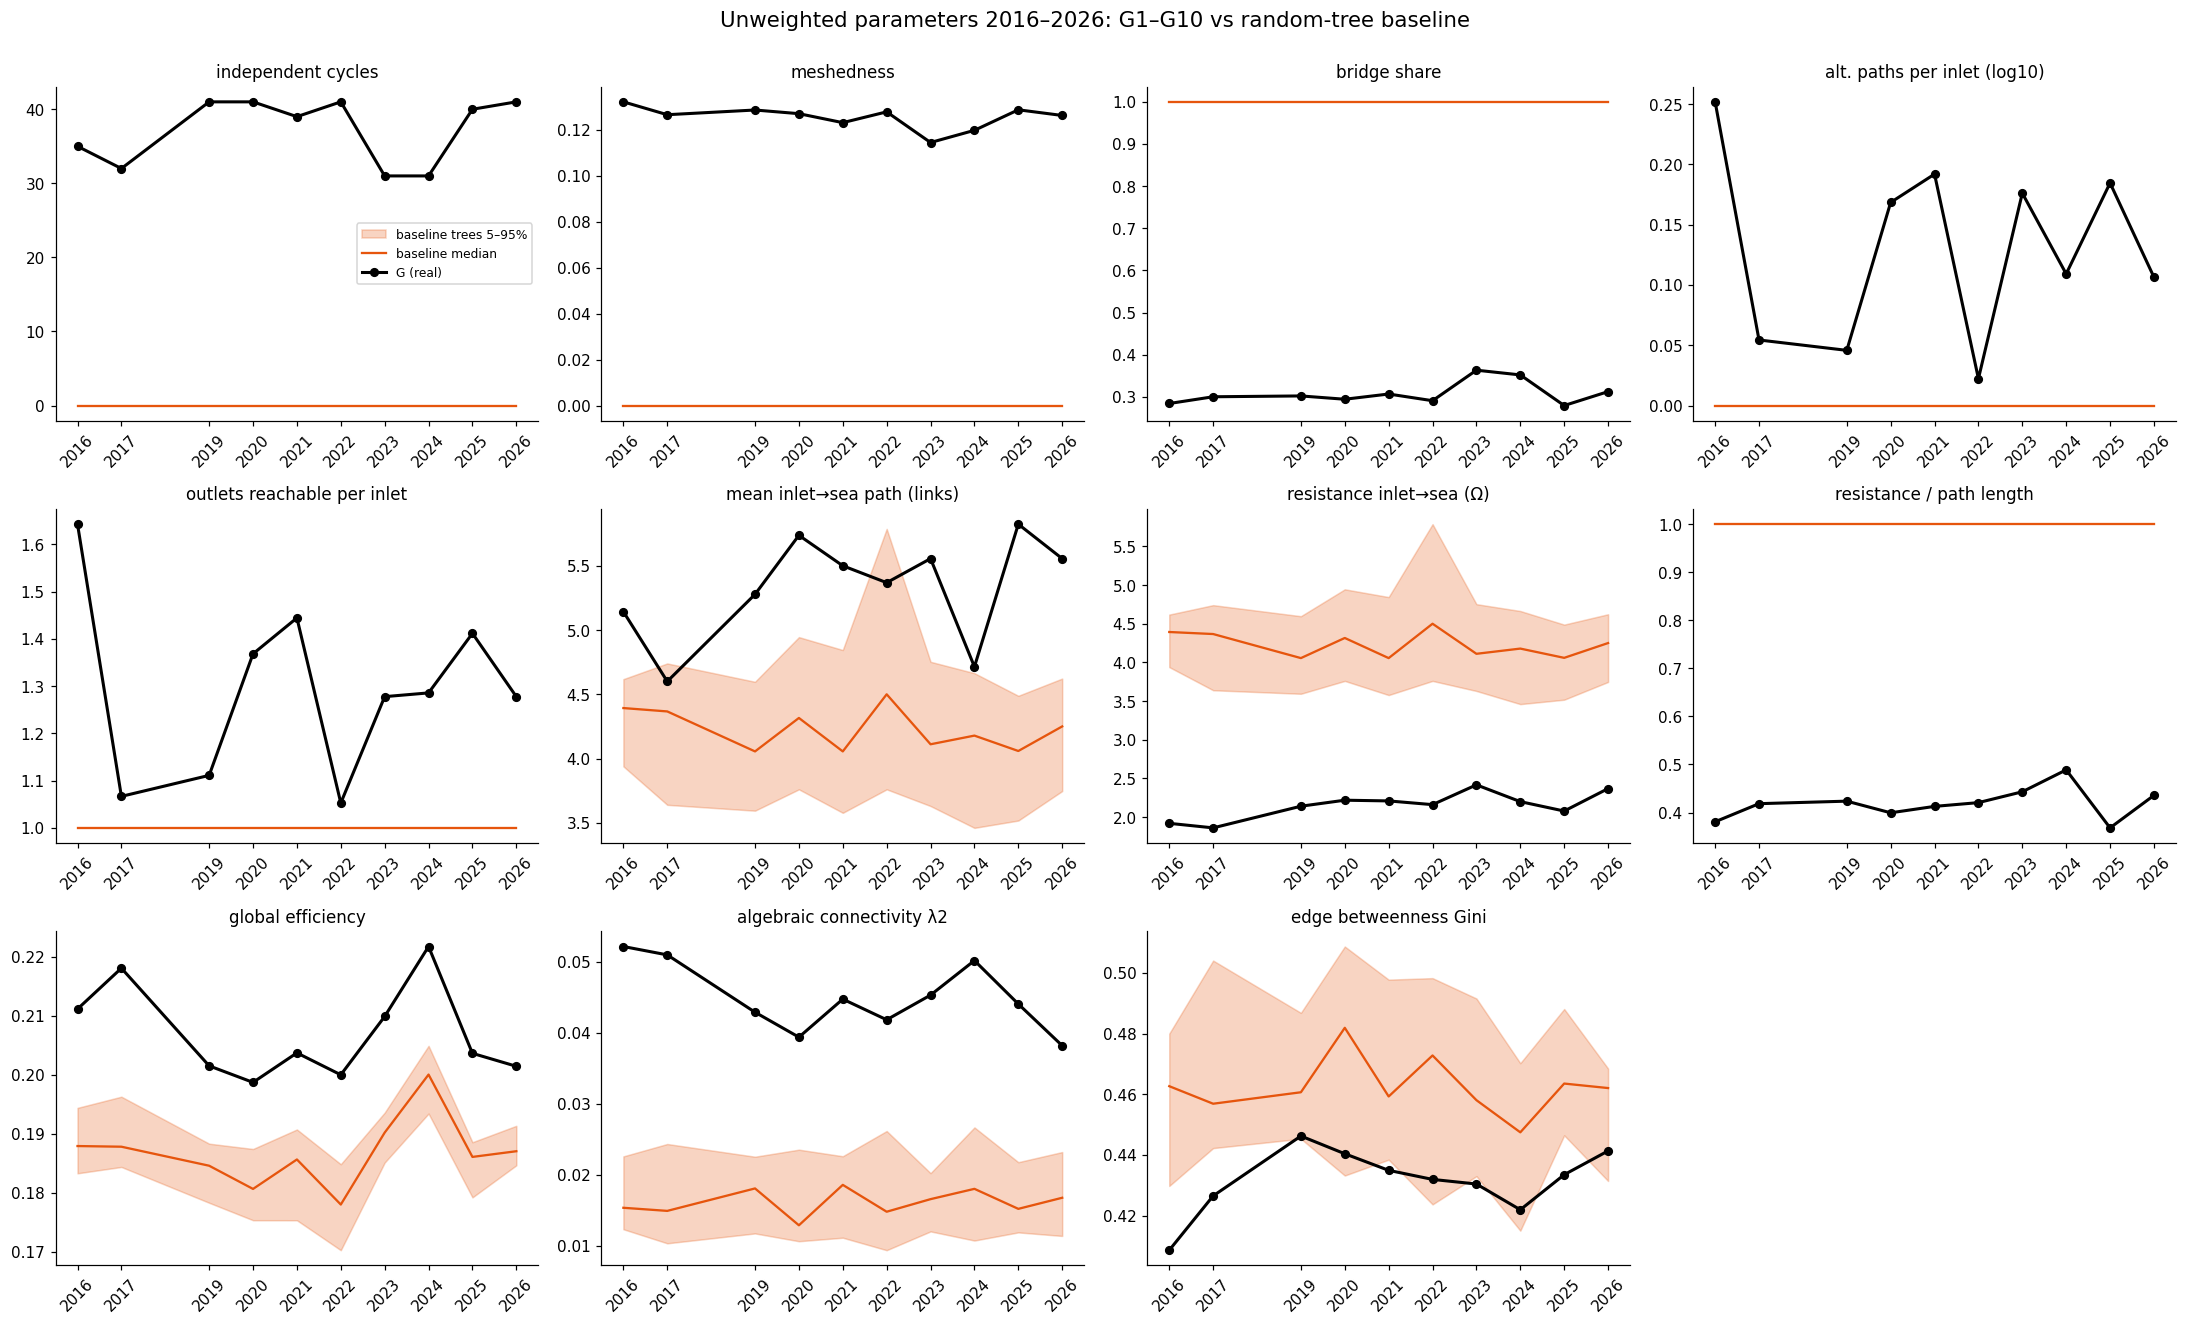

In [18]:
years = pd.to_datetime(real_u['date']).dt.year.values

def trend_grid(real, base, params, shape, figsize, title, path):
    fig, axs = plt.subplots(*shape, figsize=figsize)
    for ax, p in zip(axs.ravel(), params):
        q = base.groupby('graph')[p].quantile([0.05, 0.5, 0.95]).unstack().loc[real.index]
        ax.fill_between(years, q[0.05], q[0.95], color='#e6550d', alpha=0.25, label='baseline trees 5–95%')
        ax.plot(years, q[0.5], color='#e6550d', lw=1.5, label='baseline median')
        ax.plot(years, real[p], 'k-o', lw=2, ms=5, label='G (real)')
        ax.set_title(p, fontsize=11); ax.set_xticks(years); ax.tick_params(axis='x', rotation=45)
    for ax in axs.ravel()[len(params):]:
        ax.axis('off')
    axs.ravel()[0].legend(fontsize=8)
    plt.suptitle(title, y=1.0, fontsize=14)
    plt.tight_layout(); plt.savefig(path, dpi=110); plt.show()

params_u = ['independent cycles', 'meshedness', 'bridge share', 'alt. paths per inlet (log10)',
            'outlets reachable per inlet', 'mean inlet→sea path (links)', 'resistance inlet→sea (Ω)',
            'resistance / path length', 'global efficiency', 'algebraic connectivity λ2', 'edge betweenness Gini']
trend_grid(real_u, base_u, params_u, (3, 4), (20, 12), 'Unweighted parameters 2016–2026: G1–G10 vs random-tree baseline', f'{OUT}/trends_unweighted.png')

### Parameters that need weights (conductance = width / length)

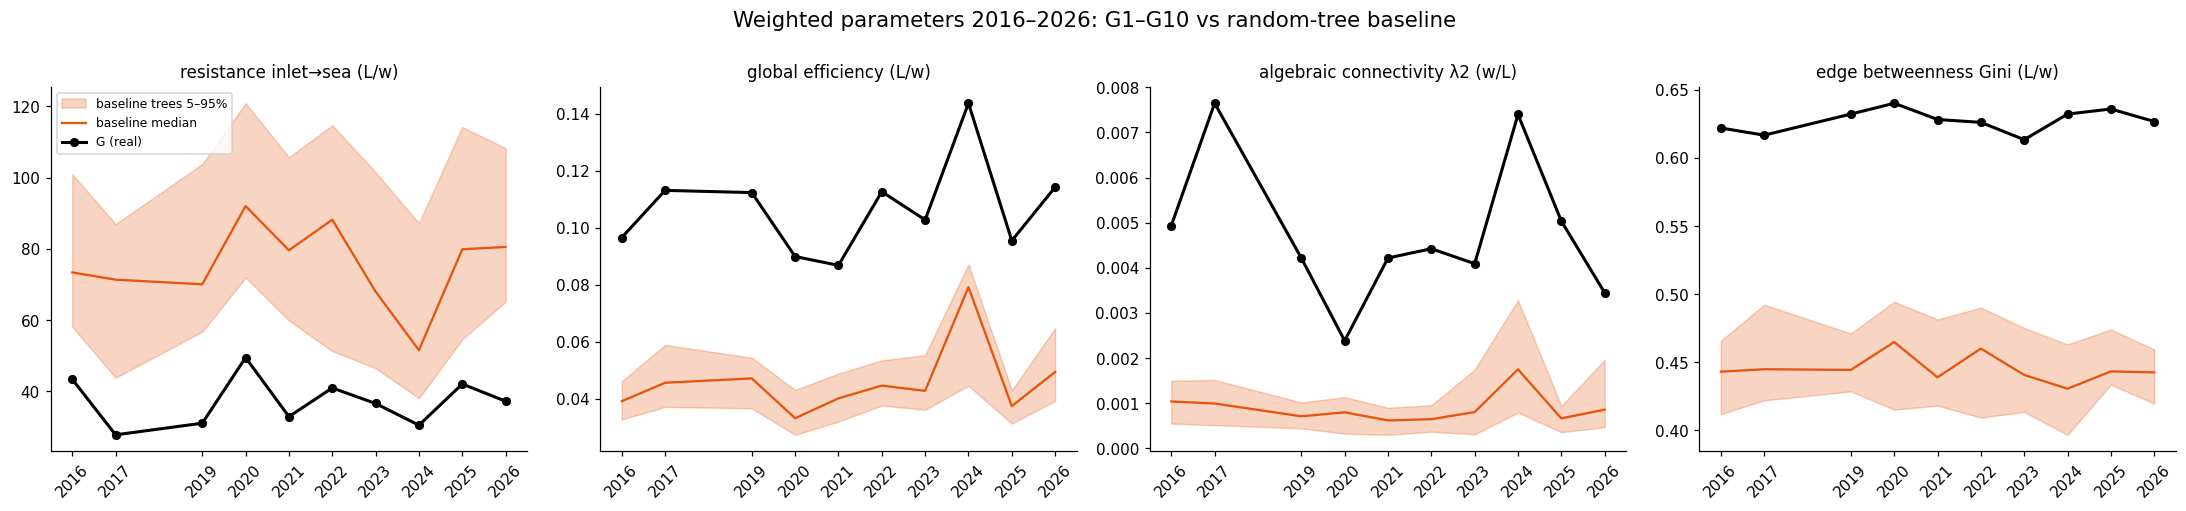

In [19]:
params_w = ['resistance inlet→sea (L/w)', 'global efficiency (L/w)', 'algebraic connectivity λ2 (w/L)', 'edge betweenness Gini (L/w)']
trend_grid(real_w, base_w, params_w, (1, 4), (20, 4.6), 'Weighted parameters 2016–2026: G1–G10 vs random-tree baseline', f'{OUT}/trends_weighted.png')

### Distance from the baseline over time (z-score)

z = (G − baseline mean) / baseline sd, for parameters that vary between random trees.
A change in z is a change in **structure** relative to a random tree on the same nodes. The weighted panel compares against trees with the same year's channel geometry.

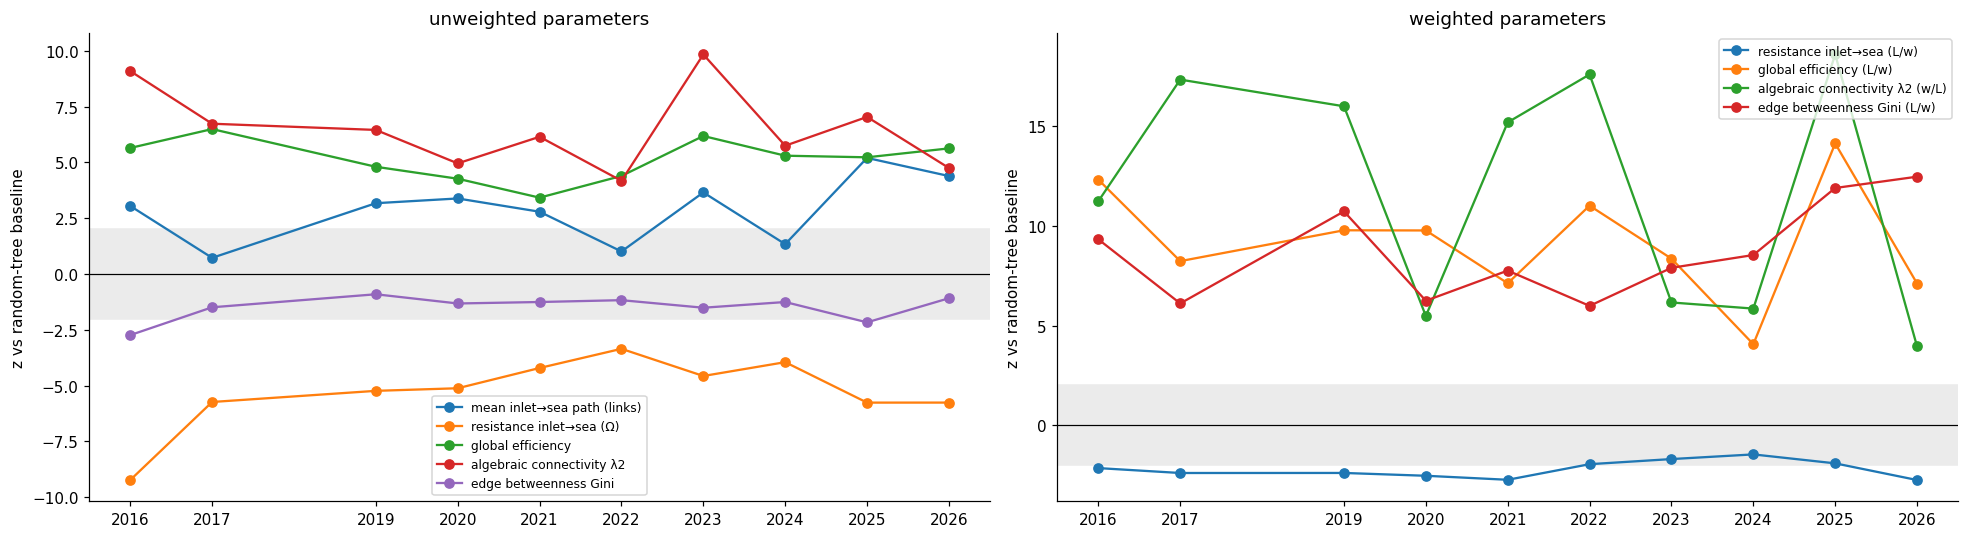

graph,G1,G2,G3,G4,G5,G6,G7,G8,G9,G10
mean inlet→sea path (links),3.0,0.7,3.2,3.4,2.8,1.0,3.7,1.3,5.2,4.4
resistance inlet→sea (Ω),-9.2,-5.7,-5.2,-5.1,-4.2,-3.4,-4.6,-4.0,-5.8,-5.8
global efficiency,5.6,6.5,4.8,4.3,3.4,4.4,6.2,5.3,5.2,5.6
algebraic connectivity λ2,9.1,6.7,6.5,5.0,6.1,4.2,9.8,5.7,7.0,4.7
edge betweenness Gini,-2.7,-1.5,-0.9,-1.3,-1.3,-1.2,-1.5,-1.3,-2.2,-1.1
resistance inlet→sea (L/w),-2.1,-2.4,-2.4,-2.5,-2.7,-1.9,-1.7,-1.5,-1.9,-2.7
global efficiency (L/w),12.3,8.2,9.8,9.8,7.1,11.0,8.4,4.1,14.1,7.1
algebraic connectivity λ2 (w/L),11.2,17.3,16.0,5.5,15.2,17.6,6.2,5.9,18.6,4.0
edge betweenness Gini (L/w),9.3,6.1,10.7,6.2,7.8,6.0,7.9,8.5,11.9,12.5


In [20]:
def zscores(real, base, ps):
    gb = base.groupby('graph')[ps]
    return (real[ps] - gb.mean().loc[real.index]) / gb.std().loc[real.index]

z_u = zscores(real_u, base_u, ['mean inlet→sea path (links)', 'resistance inlet→sea (Ω)', 'global efficiency', 'algebraic connectivity λ2', 'edge betweenness Gini'])
z_w = zscores(real_w, base_w, params_w)
z_u.to_csv(f'{OUT}/zscores_unweighted.csv'); z_w.to_csv(f'{OUT}/zscores_weighted.csv')
fig, axs = plt.subplots(1, 2, figsize=(18, 5))
for ax, z, title in zip(axs, (z_u, z_w), ('unweighted parameters', 'weighted parameters')):
    for p, c in zip(z.columns, plt.get_cmap('tab10').colors):
        ax.plot(years, z[p], '-o', color=c, label=p)
    ax.axhspan(-2, 2, color='0.92', zorder=0); ax.axhline(0, color='k', lw=0.8)
    ax.set_xticks(years); ax.set_ylabel('z vs random-tree baseline'); ax.legend(fontsize=8); ax.set_title(title)
plt.tight_layout(); plt.savefig(f'{OUT}/zscores.png', dpi=110); plt.show()
pd.concat([z_u, z_w], axis=1).round(1).T

### Simple trend test

Kendall's τ and Sen's slope for each parameter of G over the years, as in `main.ipynb`.
With 10 points it only detects strong monotonic trends. There are 15 tests here, so about one could fall below p = 0.05 by chance: treat a low p as a lead to check, not a result.

In [21]:
from scipy.stats import kendalltau, theilslopes
trend = {}
for real, ps in ((real_u, params_u), (real_w, params_w)):
    for p in ps:
        tau, pval = kendalltau(years, real[p])
        trend[p] = {'Kendall tau': tau, 'p-value': pval, 'Sen slope per year': theilslopes(real[p], years)[0],
                    'G 2016': real[p].iloc[0], 'G 2026': real[p].iloc[-1]}
trend = pd.DataFrame(trend).T
trend.to_csv(f'{OUT}/trend_tests.csv')
trend.round(4)

,Kendall tau,p-value,Sen slope per year,G 2016,G 2026
independent cycles,0.0484,0.8523,0.0000,35.0000,41.0000
meshedness,-0.2889,0.2912,-0.0006,0.1144,0.1321
bridge share,0.2444,0.3807,0.0016,0.2792,0.3631
alt. paths per inlet (log10),-0.0667,0.8618,-0.0018,0.0223,0.2518
outlets reachable per inlet,0.0000,1.0000,0.0000,1.0526,1.6429
mean inlet→sea path (links),0.4045,0.1060,0.0450,4.6000,5.8235
resistance inlet→sea (Ω),0.3778,0.1557,0.0342,1.8607,2.4169
resistance / path length,0.3333,0.2164,0.0047,0.3681,0.4888
global efficiency,-0.1111,0.7275,-0.0002,0.1987,0.2217
algebraic connectivity λ2,-0.3333,0.2164,-0.0009,0.0382,0.0521


## 5. Notes from this run

NOTES_PLACEHOLDER